In [1]:
# Importing the python libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
cleaned_customer_transaction_data = pd.read_csv(r'../dataset/artifacts/Cleaned_Data.csv')

Next is to set theme for specific plot a kind of general setting

In [3]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.1,
    palette='Spectral'
)

Distribution of Fraud and Transaction Channels

The charts above provide an initial understanding of the dataset and are important for exploratory data analysis (EDA) stage. The fraud distribution chart is used to examine the balance btw fraudulent and the legitimate transactions. This is particularly important for fraud detecttion because an imbalanced target varible can cause a machine learning model to favor the majority class and perform poorly when identifying fraudulent transaction. Understanding the level of class imbalance helps determine whether techniques such as class weighting, resampling or appropriate evaluation metrics may be required

The transaction channel distribution chart shows how transaction are distributed across different channels such as mobile, online, ATM, or other available channels. Examining this distribution helps identify dominant  or underrepresnted transaction channels and provide an initial indication of whether the channel may be relevant to fraudulant behaviours . These observation can also guide subsequent feature analysis and model development.

In [4]:
cleaned_customer_transaction_data.columns

Index(['transaction_id', 'customer_id', 'timestamp', 'home_country',
       'source_currency', 'dest_currency', 'channel', 'amount_src',
       'amount_usd', 'fee', 'exchange_rate_src_to_dest', 'device_id',
       'new_device', 'ip_address', 'ip_country', 'location_mismatch',
       'ip_risk_score', 'kyc_tier', 'account_age_days', 'device_trust_score',
       'chargeback_history_count', 'risk_score_internal', 'txn_velocity_1h',
       'txn_velocity_24h', 'corridor_risk', 'is_fraud'],
      dtype='str')

First one of the thing we do now is to visualizie the fraudulant transaction distribution how it occurred and the non-fraudulant transaction and compared the distributions

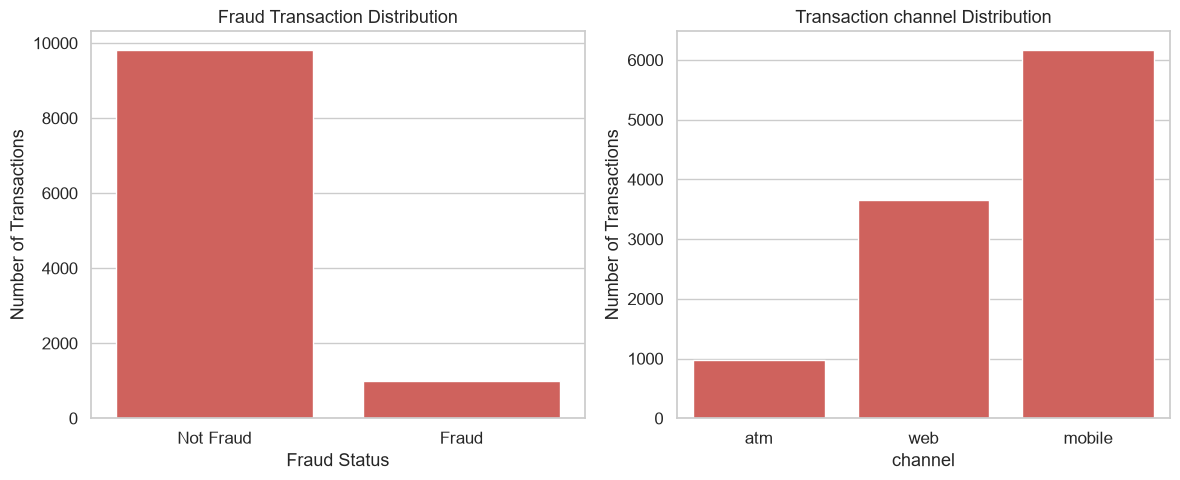

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Fraud distribution
sns.countplot(data=cleaned_customer_transaction_data, x='is_fraud',ax=axes[0])
axes[0].set_title('Fraud Transaction Distribution')
axes[0].set_xlabel('Fraud Status')
axes[0].set_ylabel('Number of Transactions')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Not Fraud', 'Fraud'])

# Channel distribution
sns.countplot(data=cleaned_customer_transaction_data, x='channel', ax=axes[1])
axes[1].set_title('Transaction channel Distribution')
axes[1].set_xlabel('channel')
axes[1].set_ylabel('Number of Transactions')

plt.tight_layout()
plt.show()




Ip Country and KYC Tier Analysis

The charts provide an overview of the distribution of transaction across IP countries and KYC tiers, while also examining their relationship with fraudulaent transactions. The IP country distribution helps identify the countries from which transactions are predominantly initiated and highlights countries that may be underrepresented in the dataset. Similarly the KYC tier distribution shows how transactions are distributed across diff levels of customer verification, providing an understanding of the composition of the customer base.

The IP country fraud chart compares fraudlent and legitimate transactions across countries. This is useful for identifying whether fraudulent transaction are concentrated within particular geographic locations which may indicate potential geographic patterns that could be relevant to frauddetection. However diff in the total number of transaction across countries should be considered when interpeting the results.

The KYC tier versus fraud chart examinsthe distribution of fraudulent and legitimate transactions across diff KYC verification levels. This analysis can help determine whether fraud occurrence varies across customer verification tires and whetherKYC status may provide useful predictive information for the fraud detection model.

Overall these visualisation helps identify potential patterns and relationships btw customerverification transaction origin and fraudulent behaviours which can inform subsequent features engineering and machine learning model development

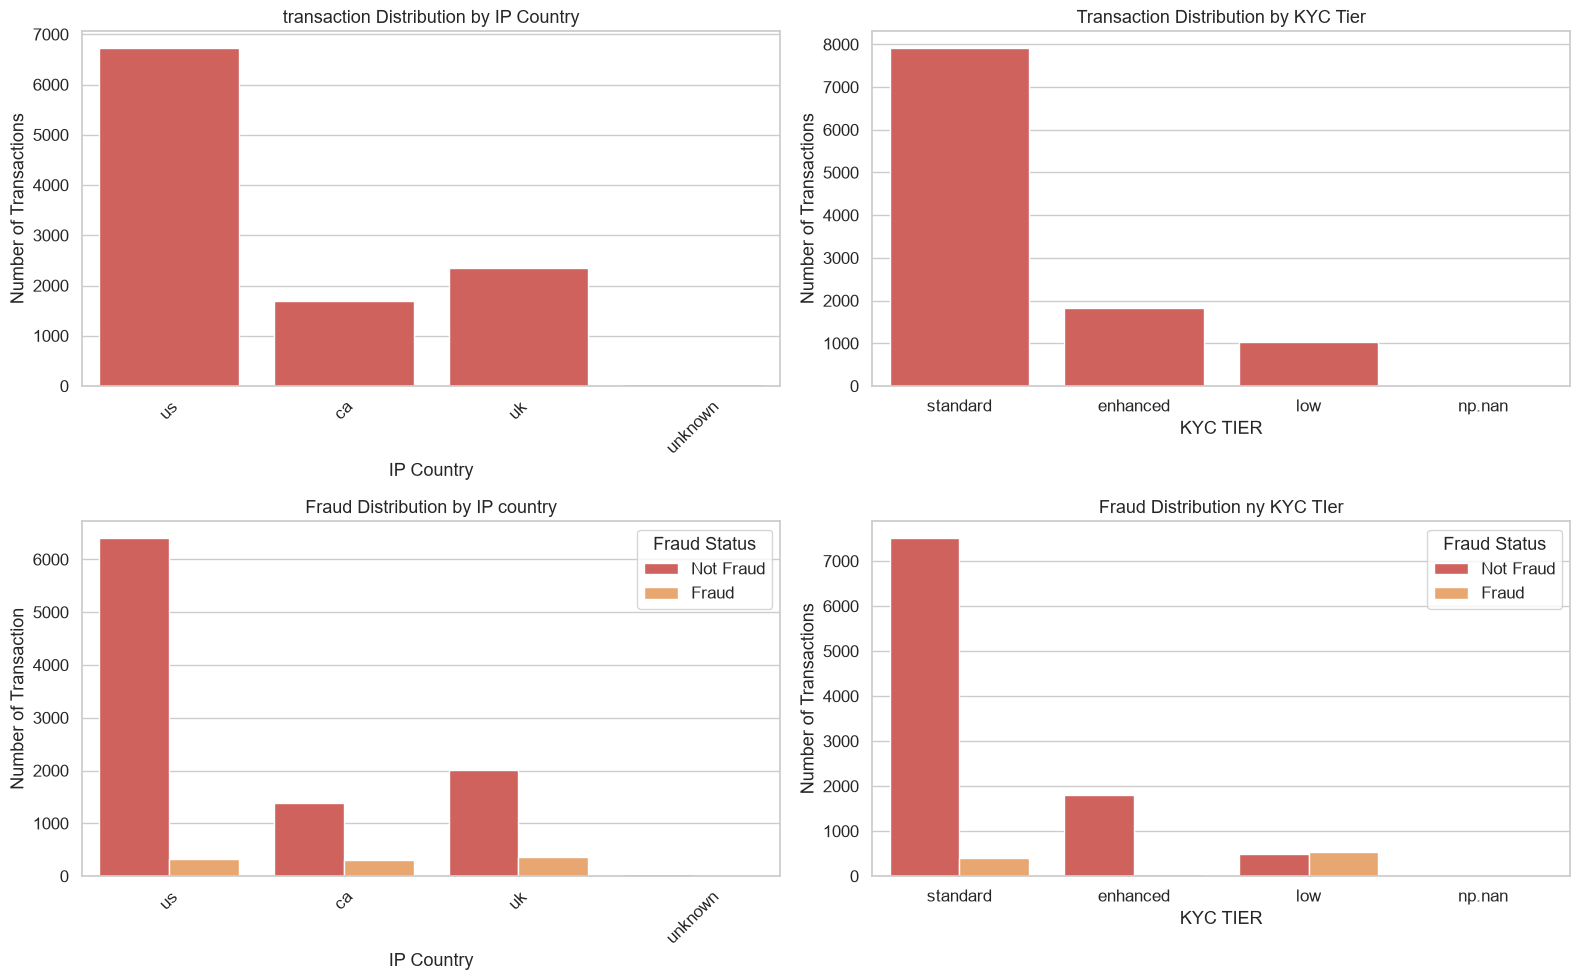

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2,2, figsize=(16, 10))

# 1. IP Country Distribution
sns.countplot(
    data=cleaned_customer_transaction_data,
    x='ip_country',
    ax=axes[0, 0]
)
axes[0, 0].set_title('transaction Distribution by IP Country')
axes[0, 0].set_xlabel('IP Country')
axes[0, 0].set_ylabel('Number of Transactions')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2, KYC TIER distribution
sns.countplot(
    data=cleaned_customer_transaction_data,
    x='kyc_tier',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Transaction Distribution by KYC Tier')
axes[0, 1].set_xlabel('KYC TIER')
axes[0, 1].set_ylabel('Number of Transactions')

# 3. IP country vs Fraud

sns.countplot(
    data=cleaned_customer_transaction_data,
    x='ip_country',
    hue='is_fraud',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Fraud Distribution by IP country')
axes[1, 0].set_xlabel('IP Country')
axes[1, 0].set_ylabel('Number of Transaction')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(title='Fraud Status', labels=['Not Fraud', 'Fraud'])


# 4. Tier vs Fraud

sns.countplot(
    data=cleaned_customer_transaction_data,
    x='kyc_tier',
    hue='is_fraud',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Fraud Distribution ny KYC TIer')
axes[1, 1].set_xlabel('KYC TIER')
axes[1, 1].set_ylabel('Number of Transactions')
axes[1, 1].legend(title='Fraud Status', labels=['Not Fraud', 'Fraud'])

plt.tight_layout()
plt.show()

Next is Fraud rate Analysis by Location Mismatch, KYC TIER and Transaction Channel

The visualizations shows fraudulent transaction behaviour varies across location mismatch KYC verification level, and transaction channel. The location mismatch, analysis indicates a substanial diff in fraud risk depending on whether a transaction occurs in an expected location. Transactions where location_mismatch = false, meaning the transaction location is consistent with the user"s expected or previously observed location, have a relatively low fraud rate of approximatly 3-5%. in contrast transaction where location_mismatch = True, indicating an unexpected or unfamiliar transaction location have a considerably higher fraud rate of over 35%. Based on the observed rates with a location mismatch are approximately 7-9 times more likely to be fraudulent than transaction without a location mismatch. This suggests that location mismatch may be an important predictive features for identifying potentially fraudelent transaction.

Th analysis of KYC tier also shows diff in fraud rist across customer verification levels. The result indicates that customers with lower levels of KYC verification have higher fraud rates while customers with enhanced verification have the lowest observed fraud risk. This suggests that the level of customers verification may provide useful information for distinguishing btw legitimate and potentially fraudulent transactions.

The transaction channel analysis provides two complementary perspectives, The fraud rate chart measures the proportion of transaction that are fraudulent within each channel while the fraud count chart measures actual number of fraudulent and non-fraudulent transactions. The results indicates thatb web transaction have a higher rate than mobile transactions. suggesting that the web channel may present a relatively higherfraud rate than mobile transaction, suggesting that the web alonside fraud rate bcos diff in the total number of transaction across channel can influenc the absolute number of fraudulent transaction

overall these finding indicates that location mismatch , KYC verification leel and transaction channel may contain meaniful signals for fraud detection, these variables should therefore be considered during feature engineering  and model developmentb while their  predictive importance should utimately be validated using statistical analysis and machine learning model evaluation

C:\Users\pc\AppData\Local\Temp\ipykernel_6604\1301255954.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_6604\1301255954.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_6604\1301255954.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


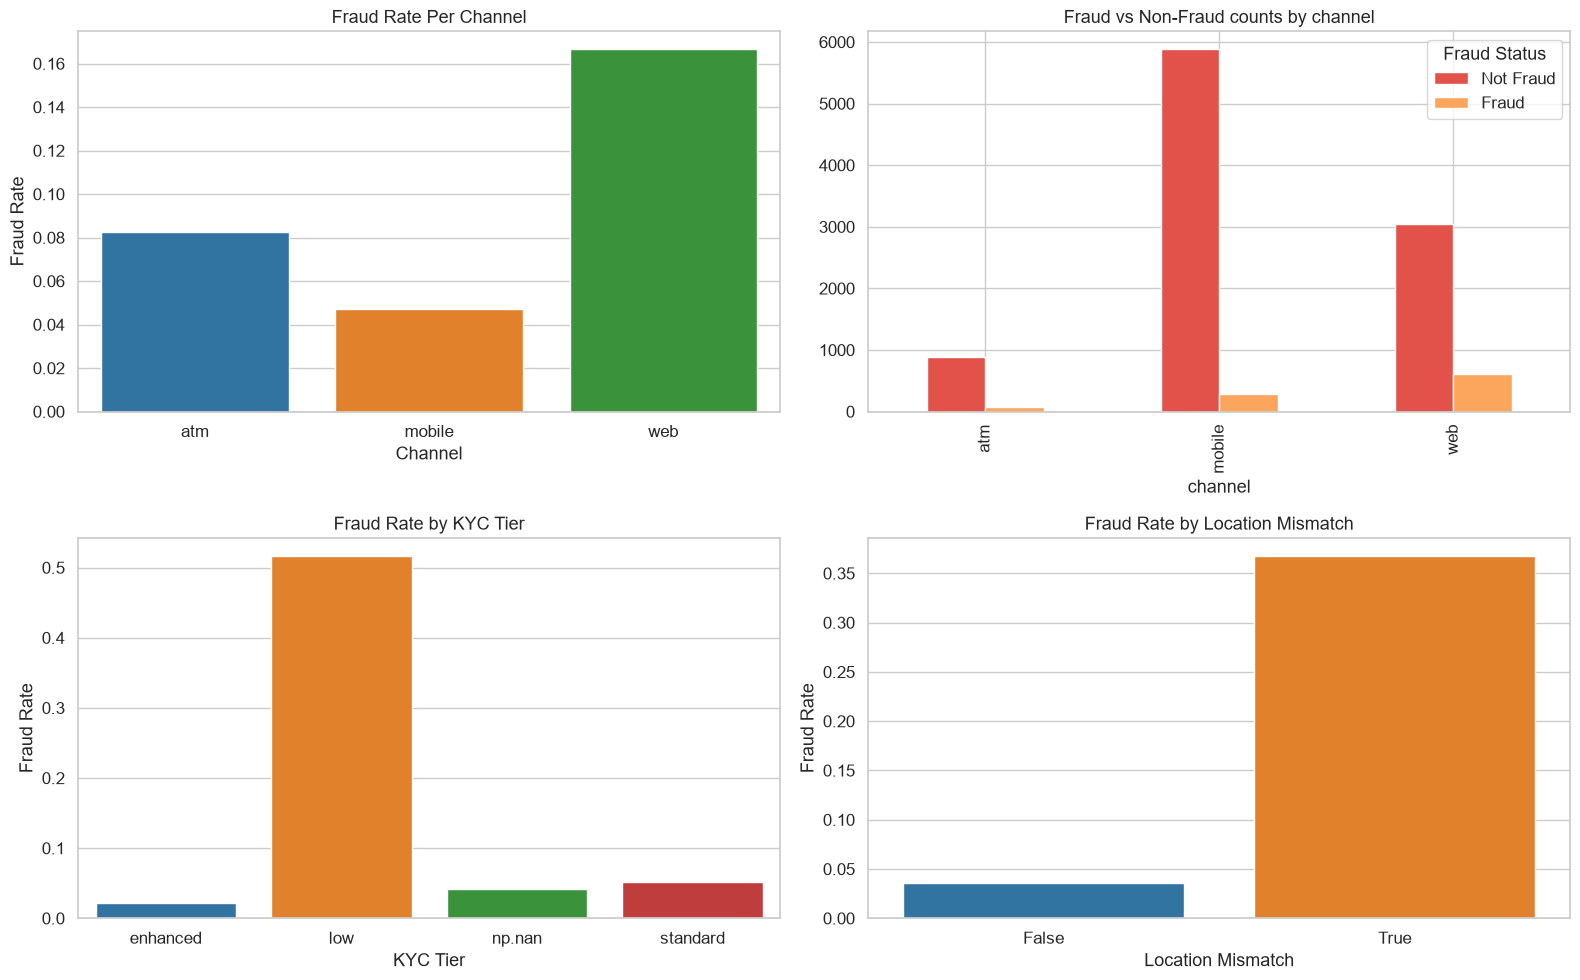

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Fraud rate per channel
channel_fraud_rate = cleaned_customer_transaction_data.groupby('channel')['is_fraud'].mean().reset_index()

sns.barplot(
    data=channel_fraud_rate,
    x='channel',
    y='is_fraud',
    ax=axes[0, 0],
    palette='tab10'
)

axes[0, 0].set_title('Fraud Rate Per Channel')
axes[0, 0].set_xlabel('Channel')
axes[0, 0].set_ylabel('Fraud Rate')

# 2. Fraud Vs Non- Fraud counts per channel

channel_counts = (
    cleaned_customer_transaction_data.groupby('channel')['is_fraud']
    .value_counts()
    .unstack(fill_value=0)
    .reset_index()
)

channel_counts = channel_counts.rename(
    columns={0: 'Not Fraud', 1: 'Fraud'}
)

channel_counts.plot(
    x='channel',
    y=['Not Fraud', 'Fraud'],
    kind='bar',
    ax=axes[0, 1]
)

axes[0, 1].set_title('Fraud vs Non-Fraud counts by channel')
axes[0, 1].set_xlabel('channel')
axes[0, 1].legend(title='Fraud Status')

# 3. Fraud rate per KYC tier
kyc_fraud_rate = cleaned_customer_transaction_data.groupby('kyc_tier')['is_fraud'].mean().reset_index()

sns.barplot(
    data=kyc_fraud_rate,
    x='kyc_tier',
    y='is_fraud',
    ax=axes[1, 0],
    palette='tab10'
)

axes[1, 0].set_title('Fraud Rate by KYC Tier')
axes[1, 0].set_xlabel('KYC Tier')
axes[1, 0].set_ylabel('Fraud Rate')

# 4. fraud rate per location mismatch

location_fraud_rate = (
    cleaned_customer_transaction_data.groupby('location_mismatch')['is_fraud']
    .mean()
    .reset_index()

)
sns.barplot(
    data=location_fraud_rate,
    x='location_mismatch',
    y='is_fraud',
    ax=axes[1, 1],
    palette='tab10'
)

axes[1, 1].set_title('Fraud Rate by Location Mismatch')
axes[1, 1].set_xlabel('Location Mismatch')
axes[1, 1].set_ylabel('Fraud Rate')


plt.tight_layout()
plt.show()

Transaction Velocity and Fraud Risk

The chart examins the relationship btw transaction velocity and the likelihood of a transaction being fraudulent over both 1-hour and 24-hour periods. The results shows s strong relationship btw unusually high transaction frequency and fruadulent activity in th dataset.

For 1-hour transaction velocity accounts making only one ro two transaction within an hour have a very low fraud rate, representing relatively normal transaction behavor However a substantial increase  occurs around the third transaction where the fraud rate rises sharply to above 80%. The fraud rate remains particularly high btw approximately 3 and 5 transaction per hour reaching around 70 to 80 % .The pattern suggest that rapid burst of transaction may be an important indicator of compromise accounts  or automated fraudulent activity Although the fraud rate declined after five transactions and reaches approximately 45% around eight transactionper hr it remains considerably higher than the  baseline.

a similar pattern can be observed for 24hrs transaction velocity Accounts making btw 0 and 3 transaction per day
have an extremely low observed fraud rate.however the fraud rate incresaes substantially as transaction freq rises reaching approximately 75% around five transactions per day. Btw approximately 5 and 8 transactionthe fraud rate remain relatively high at around 70 to 80 %despite a slight decline around eight transaction the rate then increases againapproacing 100%at around 10 transactions per day in the observed data.
overall the result suggest that transaction velocity is an impotantbehavioural sinal for fraud detection Higher transaction frequency particularly when transaction occurs in rapid burst is strong associated wth fraudulent activity in this dataset. Thses velocity basedfeature txn_velocity_1h and txn_velocity_24h may therefore provde valuable predictive information for the machine learning models However the observedrate should be interpreted as dataset - specific pattern rather than universal fraud thresholds and their importance should be validated during model and evaluation

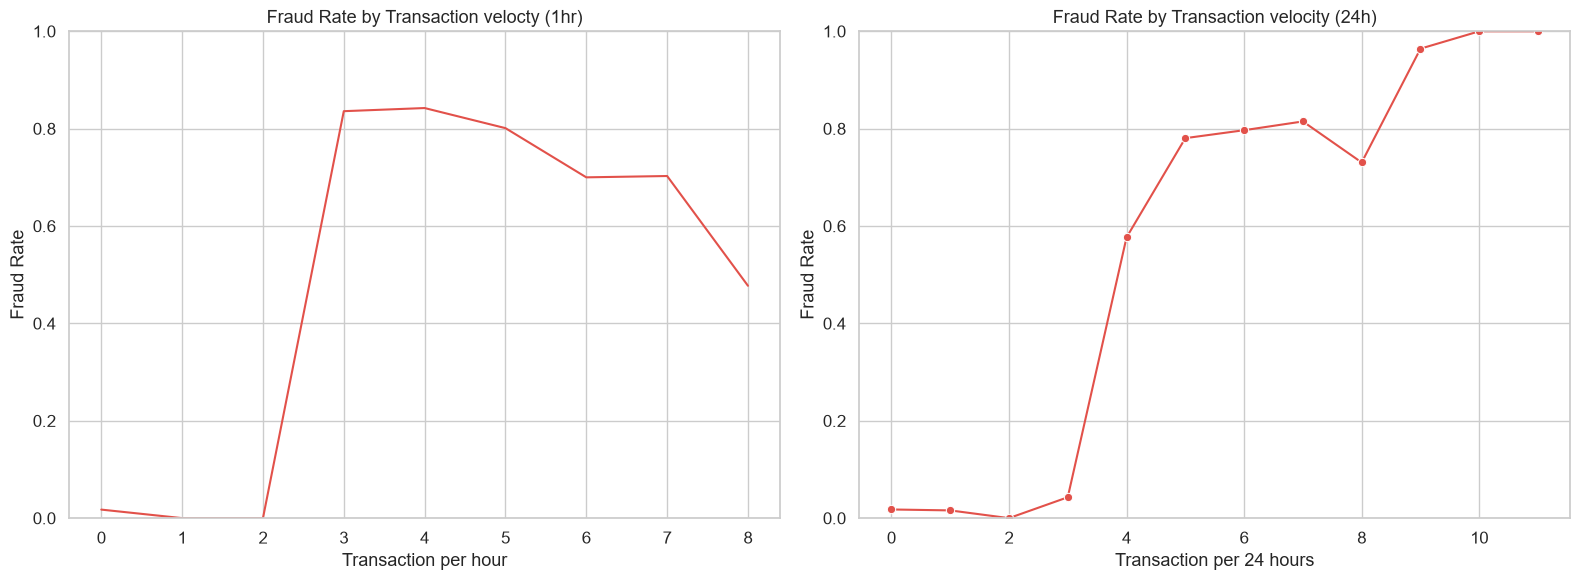

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Fraud rate by transaction  velocity (1 hour)
txn_velocity_1h = (
    cleaned_customer_transaction_data.groupby('txn_velocity_1h')['is_fraud']
    .mean()
    .reset_index()
)

sns.lineplot(
    data=txn_velocity_1h,
    x='txn_velocity_1h',
    y='is_fraud',
    ax=axes[0]
)

axes[0].set_title('Fraud Rate by Transaction velocty (1hr)')
axes[0].set_xlabel('Transaction per hour')
axes[0].set_ylabel('Fraud Rate')
axes[0].set_ylim(0, 1)

# 2. Fraud rate by transaction velocity (24hrs hours)

txn_velocity_24h = (
    cleaned_customer_transaction_data.groupby('txn_velocity_24h')['is_fraud']
    .mean()
    .reset_index()
)

sns.lineplot(
    data=txn_velocity_24h,
    x='txn_velocity_24h',
    y='is_fraud',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Fraud Rate by Transaction velocity (24h)')
axes[1].set_xlabel('Transaction per 24 hours')
axes[1].set_ylabel('Fraud Rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

